# Job Salary Prediction & Analytics



## 1. Imports and Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 100)

## 2. Load and Inspect the Dataset

In [2]:
import kagglehub
import os

# Download the dataset automatically using kagglehub
download_dir = kagglehub.dataset_download("hosan707/job-salary-prediction-dataset")

# Find the CSV file inside the downloaded directory
files = os.listdir(download_dir)
csv_files = [f for f in files if f.endswith('.csv')]

if csv_files:
    DATA_PATH = os.path.join(download_dir, csv_files[0])
else:
    # Fallback default filename if no CSV was detected in the root of the folder
    DATA_PATH = os.path.join(download_dir, "job_salary_prediction_dataset.csv")

raw_df = pd.read_csv(DATA_PATH)

print("Dataset shape:", raw_df.shape)
print("\nColumns:")
print(raw_df.columns.tolist())
display(raw_df.head())
display(raw_df.info())

100%|██████████| 3.00M/3.00M [00:00<00:00, 143MB/s]

Extracting files...


Dataset shape: (250000, 10)

Columns:
['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications', 'salary']


,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB


None

In [3]:
# Standardize column names and map common aliases to expected names.
df = raw_df.copy()
df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

aliases = {
    "job_title": ["job_title", "job_role", "title"],
    "experience_years": ["experience_years", "years_experience", "experience"],
    "education_level": ["education_level", "education", "education_required"],
    "skills_count": ["skills_count", "number_of_skills"],
    "industry": ["industry", "industry_type"],
    "company_size": ["company_size", "organization_size"],
    "location": ["location", "company_location", "country"],
    "remote_work": ["remote_work", "remote_ratio", "work_mode"],
    "certifications": ["certifications", "certification_count"],
    "salary": ["salary", "annual_salary", "salary_usd", "salary_in_usd"]
}

rename_map = {}
for standard, options in aliases.items():
    for option in options:
        if option in df.columns:
            rename_map[option] = standard
            break
df = df.rename(columns=rename_map)

required = ["job_title", "experience_years", "education_level",
            "skills_count", "industry", "company_size", "location",
            "remote_work", "certifications", "salary"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(
        f"These expected columns were not found: {missing}. "
        f"Actual columns: {df.columns.tolist()}. Update the aliases in this cell."
    )

# Keep relevant project columns only; do not use demographic features.
df = df[required].copy()

numeric_cols = ["experience_years", "skills_count", "certifications", "salary"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

categorical_cols = ["job_title", "education_level", "industry",
                    "company_size", "location", "remote_work"]
for col in categorical_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

before = len(df)
df = df.dropna(subset=["salary", "job_title"])
df = df[df["salary"] > 0]
print(f"Rows retained: {len(df):,} / {before:,}")
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))
display(df.describe(include="all").T)

Rows retained: 250,000 / 250,000
Missing values by column:


,missing_count
job_title,0
experience_years,0
education_level,0
skills_count,0
industry,0
company_size,0
location,0
remote_work,0
certifications,0
salary,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_title,250000,12,Backend Developer,21125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience_years,250000.0,NaN,NaN,NaN,10.005408,6.060602,0.0,5.0,10.0,15.0,20.0
education_level,250000,5,Master,50352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
skills_count,250000.0,NaN,NaN,NaN,9.997812,5.479288,1.0,5.0,10.0,15.0,19.0
industry,250000,10,Finance,25393,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,250000,5,Large,50254,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,250000,10,Australia,25258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
remote_work,250000,3,No,83621,NaN,NaN,NaN,NaN,NaN,NaN,NaN
certifications,250000.0,NaN,NaN,NaN,2.491928,1.706475,0.0,1.0,2.0,4.0,5.0
salary,250000.0,NaN,NaN,NaN,145718.080524,37407.952729,31867.0,119358.0,143453.0,169492.0,333046.0


## 3. Exploratory Data Analysis (EDA)

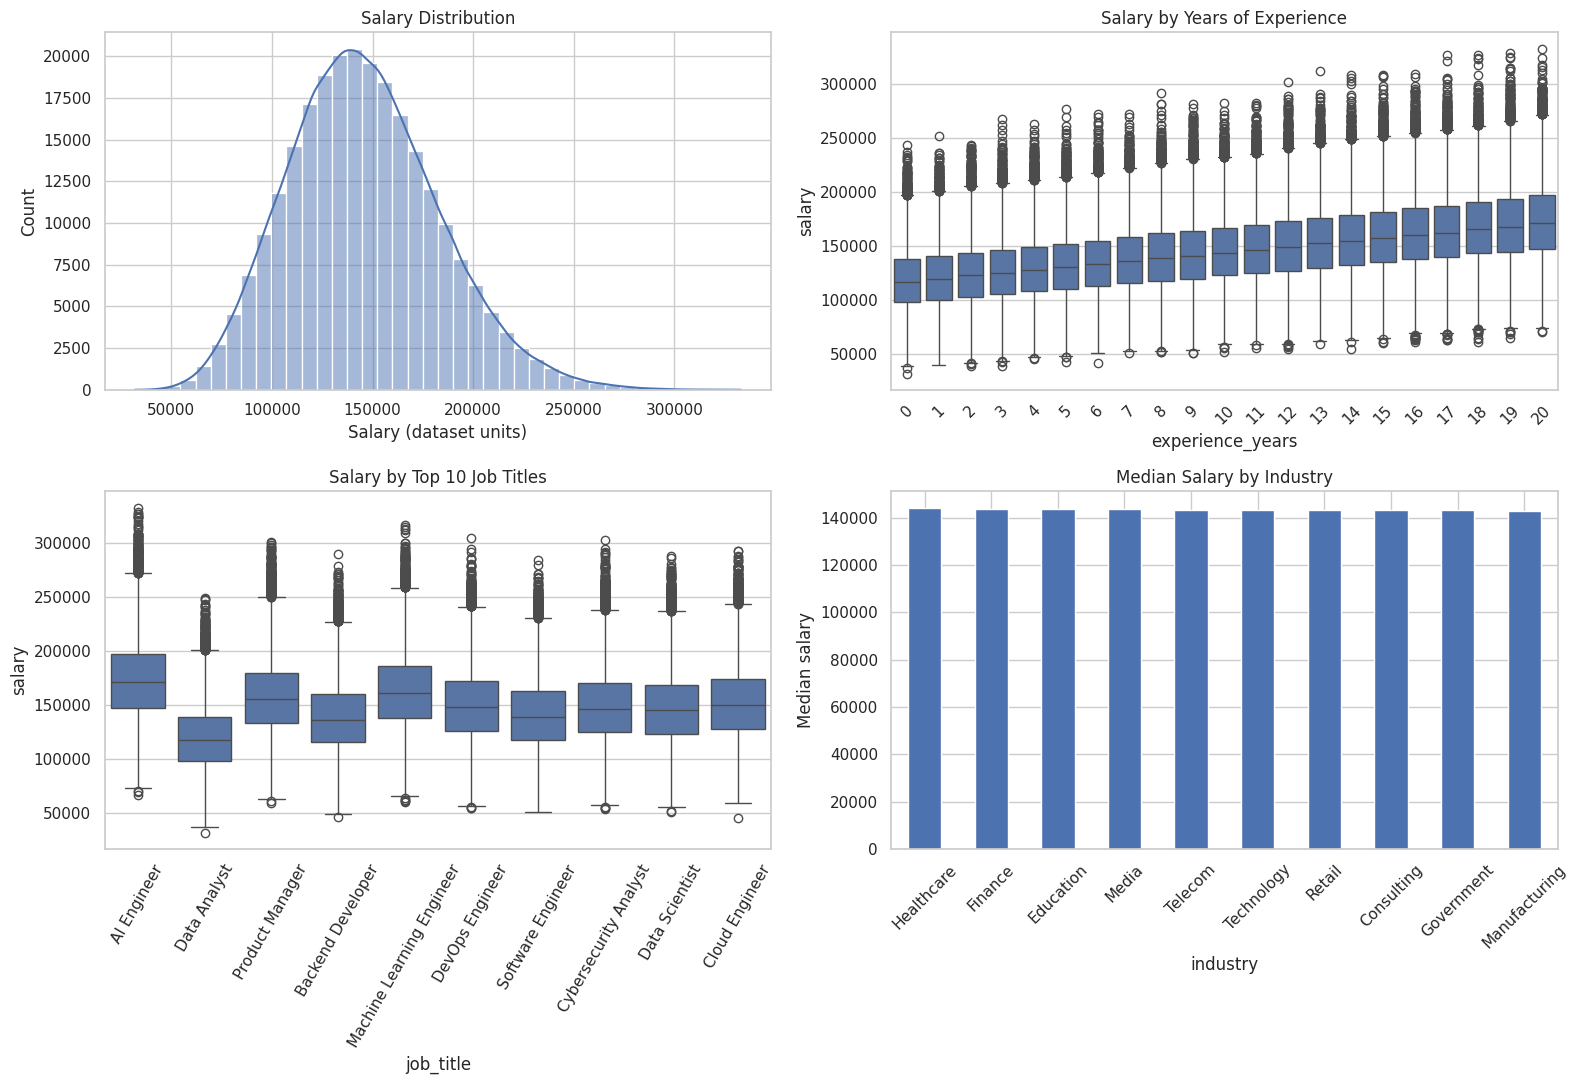

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.histplot(df["salary"], bins=40, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Salary Distribution")
axes[0, 0].set_xlabel("Salary (dataset units)")

sns.boxplot(data=df, x="experience_years", y="salary", ax=axes[0, 1])
axes[0, 1].set_title("Salary by Years of Experience")
axes[0, 1].tick_params(axis="x", rotation=45)

top_jobs = df["job_title"].value_counts().head(10).index
sns.boxplot(data=df[df["job_title"].isin(top_jobs)],
            x="job_title", y="salary", ax=axes[1, 0])
axes[1, 0].set_title("Salary by Top 10 Job Titles")
axes[1, 0].tick_params(axis="x", rotation=60)

industry_salary = df.groupby("industry")["salary"].median().sort_values(ascending=False)
industry_salary.plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Median Salary by Industry")
axes[1, 1].set_ylabel("Median salary")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

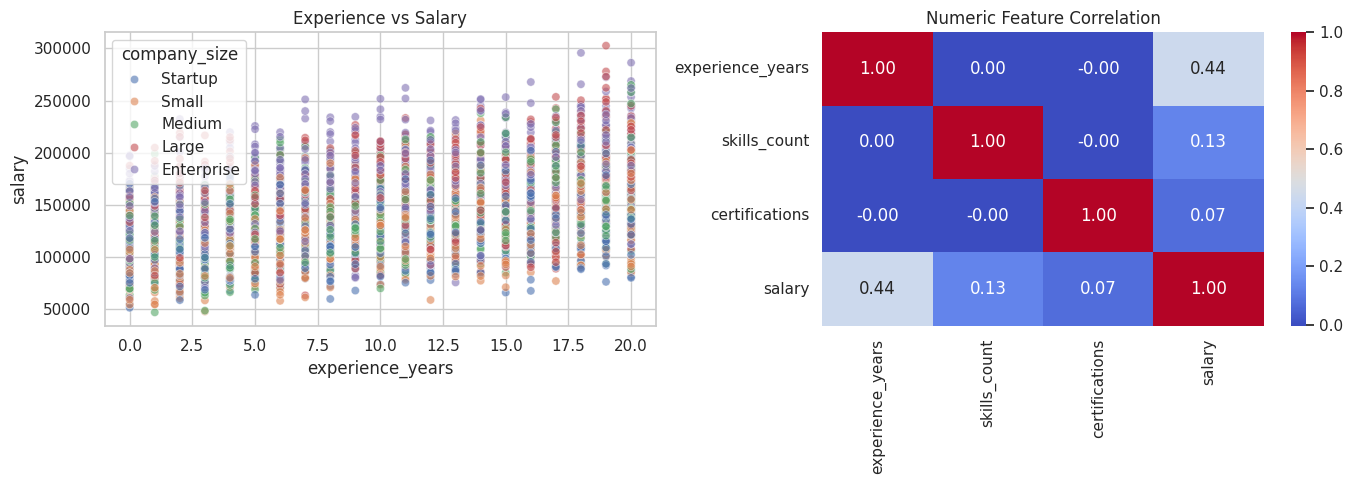

In [5]:
# Feature relationships and data quality
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(
    data=df.sample(min(5000, len(df)), random_state=RANDOM_STATE),
    x="experience_years", y="salary", hue="company_size",
    alpha=0.6, ax=axes[0]
)
axes[0].set_title("Experience vs Salary")

corr = df[["experience_years", "skills_count", "certifications", "salary"]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Numeric Feature Correlation")
plt.tight_layout()
plt.show()

## 4. Probability and Sampling

In [6]:
population_mean = df["salary"].mean()
population_std = df["salary"].std()

sample = df["salary"].sample(n=min(30, len(df)), random_state=RANDOM_STATE)
print(f"Dataset mean salary: {population_mean:,.2f}")
print(f"Sample mean salary:  {sample.mean():,.2f}")
print(f"Dataset standard deviation: {population_std:,.2f}")

Dataset mean salary: 145,718.08
Sample mean salary:  149,443.07
Dataset standard deviation: 37,407.95


## 5. Central Limit Theorem (CLT)

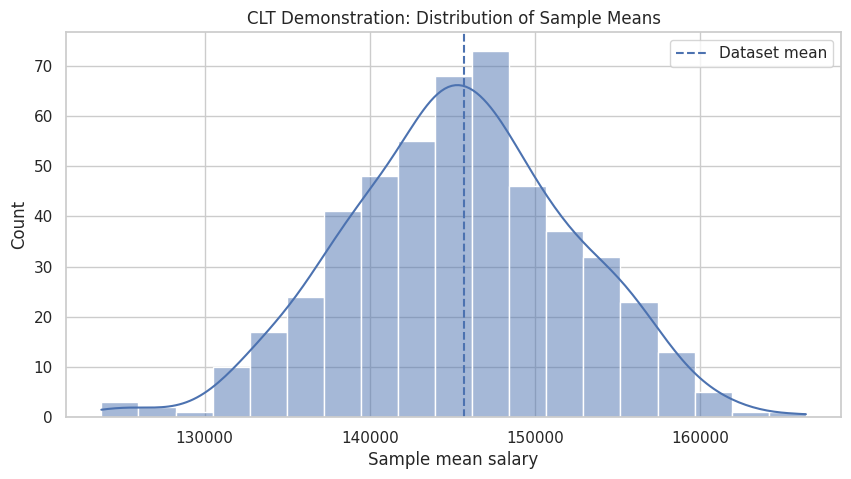

In [7]:
sample_size = min(30, len(df))
sample_means = [
    df["salary"].sample(sample_size, replace=True).mean()
    for _ in range(500)
]

plt.figure(figsize=(10, 5))
sns.histplot(sample_means, kde=True)
plt.axvline(population_mean, linestyle="--", label="Dataset mean")
plt.title("CLT Demonstration: Distribution of Sample Means")
plt.xlabel("Sample mean salary")
plt.legend()
plt.show()

## 6. Hypothesis Testing

In [8]:
# One-sample t-test: compare mean salary with the dataset's median.
# H0: population mean salary equals the dataset median.
# Note: this is a demonstration; the median is calculated from this dataset.
reference_value = df["salary"].median()
t_stat, p_value = stats.ttest_1samp(df["salary"].dropna(), popmean=reference_value)

print(f"Reference value (dataset median): {reference_value:,.2f}")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.6g}")
print("Decision at alpha=0.05:",
      "Reject H0" if p_value < 0.05 else "Fail to reject H0")

Reference value (dataset median): 143,453.00
t-statistic: 30.2754
p-value: 5.6001e-201
Decision at alpha=0.05: Reject H0


## 7. Categorical and Multi-Group Testing

In [9]:
# Chi-square test: association between education level and company size.
contingency = pd.crosstab(df["education_level"], df["company_size"])
chi2, chi_p, dof, expected = stats.chi2_contingency(contingency)
print(f"Chi-square statistic: {chi2:.3f}")
print(f"p-value: {chi_p:.6g}")
print(f"Degrees of freedom: {dof}")

# ANOVA: compare salary across the most common industries (where sample size permits).
top_industries = df["industry"].value_counts().head(5).index
groups = [
    df.loc[df["industry"] == industry, "salary"].dropna().values
    for industry in top_industries
]
groups = [g for g in groups if len(g) >= 2]
if len(groups) >= 2:
    f_stat, anova_p = stats.f_oneway(*groups)
    print(f"ANOVA F-statistic: {f_stat:.3f}")
    print(f"ANOVA p-value: {anova_p:.6g}")
else:
    print("Not enough industry groups for ANOVA.")

Chi-square statistic: 19.039
p-value: 0.266639
Degrees of freedom: 16
ANOVA F-statistic: 0.736
ANOVA p-value: 0.567156


## 8. Linear Regression — Salary Prediction

In [10]:
# Regression uses the same job-related inputs as the Streamlit app.
feature_cols = [
    "job_title", "experience_years", "education_level", "skills_count",
    "industry", "company_size", "location", "remote_work", "certifications"
]
target_col = "salary"

X = df[feature_cols].copy()
y = df[target_col].copy()

categorical_features = [
    "job_title", "education_level", "industry",
    "company_size", "location", "remote_work"
]
numeric_features = ["experience_years", "skills_count", "certifications"]

preprocessor = ColumnTransformer([
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
reg_predictions = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, reg_predictions)
rmse = np.sqrt(mean_squared_error(y_test, reg_predictions))
r2 = r2_score(y_test, reg_predictions)

print("Linear Regression Evaluation")
print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

Linear Regression Evaluation
MAE:  5,436.10
RMSE: 7,125.52
R²:   0.9635


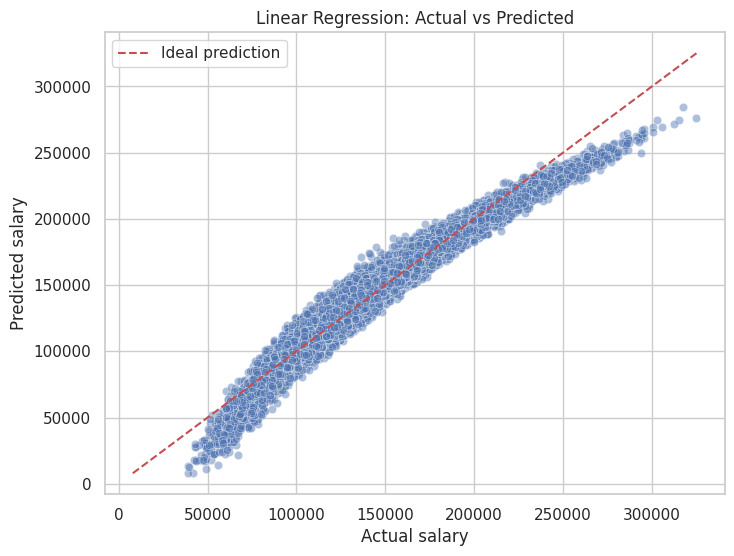

In [11]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=reg_predictions, alpha=0.45)
lower = min(y_test.min(), reg_predictions.min())
upper = max(y_test.max(), reg_predictions.max())
plt.plot([lower, upper], [lower, upper], "r--", label="Ideal prediction")
plt.xlabel("Actual salary")
plt.ylabel("Predicted salary")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.show()

## 9. Logistic Regression — Salary Class Prediction

In [12]:
# Convert salary into Low / Medium / High classes using quantile cutoffs.
# This creates balanced-enough categories and keeps the original salary as target for regression.
q1, q2 = df["salary"].quantile([1/3, 2/3]).tolist()

def salary_band(value):
    if value <= q1:
        return "Low"
    elif value <= q2:
        return "Medium"
    return "High"

df["Salary_Class"] = df["salary"].apply(salary_band)

X_cls = df[feature_cols].copy()
y_cls = df["Salary_Class"].copy()

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=RANDOM_STATE,
    stratify=y_cls
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1500, class_weight="balanced", solver="lbfgs"
    ))
])

logistic_model.fit(X_train_cls, y_train_cls)
class_predictions = logistic_model.predict(X_test_cls)

print("Logistic Regression Evaluation")
print(f"Accuracy: {accuracy_score(y_test_cls, class_predictions):.4f}")
print(classification_report(y_test_cls, class_predictions, zero_division=0))

Logistic Regression Evaluation
Accuracy: 0.9193
              precision    recall  f1-score   support

        High       0.95      0.94      0.94     16667
         Low       0.94      0.93      0.94     16666
      Medium       0.87      0.89      0.88     16667

    accuracy                           0.92     50000
   macro avg       0.92      0.92      0.92     50000
weighted avg       0.92      0.92      0.92     50000



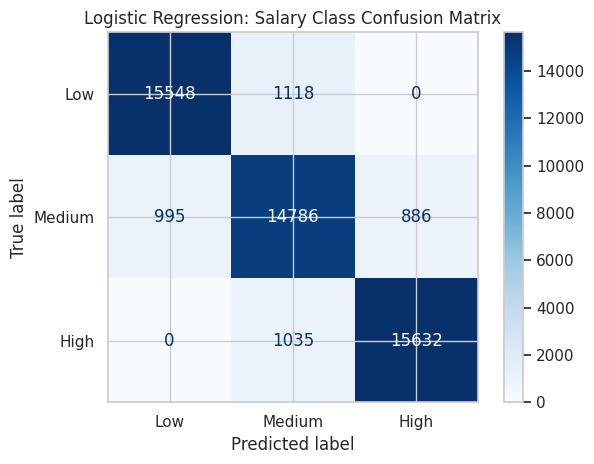

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test_cls, class_predictions,
    labels=["Low", "Medium", "High"],
    cmap="Blues",
    xticks_rotation=0
)
plt.title("Logistic Regression: Salary Class Confusion Matrix")
plt.tight_layout()
plt.show()

## 10. Export Clean Data for Streamlit

In [14]:
# The Streamlit app trains its own models from this clean, non-demographic dataset.
streamlit_columns = feature_cols + ["salary", "Salary_Class"]
df[streamlit_columns].to_csv("job_salary_clean.csv", index=False)

print("Saved job_salary_clean.csv")
print("Rows:", len(df))
print("Features:", feature_cols)
print("Salary class distribution:")
display(df["Salary_Class"].value_counts().to_frame("records"))

Saved job_salary_clean.csv
Rows: 250000
Features: ['job_title', 'experience_years', 'education_level', 'skills_count', 'industry', 'company_size', 'location', 'remote_work', 'certifications']
Salary class distribution:


,records
Salary_Class,
Medium,83334
Low,83333
High,83333
